# Chapter 12: Ratios Run the World

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** learn to name what is being compared, what counts as one, and which base a percent is of. You will compare two package labels in both orders, turn 18 out of 24 into a percent, see why up 20 percent then down 20 percent does not return to 100, and compare unit prices.

A note before we start: the code cells are optional reading. You do not need to run them or understand them. The results and the pictures are shown right below each one, so you can read straight through like a book.

In [1]:
import math
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from matplotlib.patches import Rectangle

TEAL, GOLD, TERRA, NAVY, INK, GREY, LIGHT = "#1f7a80", "#c9a227", "#c4552d", "#1f3a5f", "#222222", "#777777", "#dddddd"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def frac(x):
    """Write a Fraction the plain way: 3/4, or 2 for a whole number."""
    x = Fraction(x)
    return str(x.numerator) if x.denominator == 1 else f"{x.numerator}/{x.denominator}"

def mixed(x):
    """Write a Fraction as a mixed number: 11/4 becomes 2 3/4."""
    x = Fraction(x)
    whole, rem = divmod(x.numerator, x.denominator)
    if rem == 0:
        return str(whole)
    if whole == 0:
        return f"{rem}/{x.denominator}"
    return f"{whole} {rem}/{x.denominator}"

def bare(ax):
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)

## 1. The order states the question

**Question in plain words:** Is 18 to 12 the same comparison as 12 to 18?

$$\frac{18\ \text{oz}}{12\ \text{oz}} = \frac32 \qquad\qquad \frac{12\ \text{oz}}{18\ \text{oz}} = \frac23$$

**What the symbols mean:** oz means ounces. The first amount goes on top, the second on the bottom. The bottom amount is what counts as one. Label A holds 18 oz, Label B holds 12 oz.

In [2]:
top, bottom = 18, 12
g = math.gcd(top, bottom)
ratio = Fraction(top, bottom)
print(f"A compared with B: {top} oz / {bottom} oz")
print(f"divide both by {g}: {top} / {g} = {top//g} and {bottom} / {g} = {bottom//g}")
print(f"ratio = {top} oz / {bottom} oz = {frac(ratio)}  (the ounces cancel, no unit)")
print(f"A holds {frac(ratio)} of one B amount: one whole copy of B plus {frac(ratio - 1)} of another")
print(f"reversed: {bottom} oz / {top} oz = {frac(1/ratio)}, B holds only part of one A amount")

print()
print("Other Label B amounts, A compared with B and B compared with A:")
for b in [12, 18, 24]:
    r = Fraction(18, b)
    print(f"  B = {b} oz: 18 / {b} = {frac(r)}   and   {b} / 18 = {frac(1/r)}")
print()
print("Chapter practice: 12 oz / 6 oz =", frac(Fraction(12,6)), "and 6 oz / 12 oz =", frac(Fraction(6,12)))

A compared with B: 18 oz / 12 oz
divide both by 6: 18 / 6 = 3 and 12 / 6 = 2
ratio = 18 oz / 12 oz = 3/2  (the ounces cancel, no unit)
A holds 3/2 of one B amount: one whole copy of B plus 1/2 of another
reversed: 12 oz / 18 oz = 2/3, B holds only part of one A amount

Other Label B amounts, A compared with B and B compared with A:
  B = 12 oz: 18 / 12 = 3/2   and   12 / 18 = 2/3
  B = 18 oz: 18 / 18 = 1   and   18 / 18 = 1
  B = 24 oz: 18 / 24 = 3/4   and   24 / 18 = 4/3

Chapter practice: 12 oz / 6 oz = 2 and 6 oz / 12 oz = 1/2


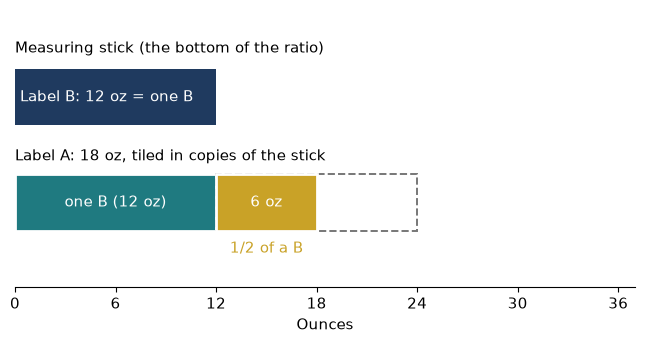

In [3]:
def order_picture(top=18, bottom=12, tn="A", bn="B"):
    whole, rest = divmod(top, bottom)
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.barh([1.6], [bottom], height=0.55, color=NAVY)
    ax.text(0.3, 1.6, f"Label {bn}: {bottom} oz = one {bn}", va="center", color="white")
    ax.text(0, 2.0, "Measuring stick (the bottom of the ratio)", va="bottom")
    x = 0
    for t in range(whole):
        ax.add_patch(Rectangle((x, 0.3), bottom, 0.55, facecolor=TEAL, edgecolor="white", lw=2))
        ax.text(x + bottom/2, 0.575, f"one {bn} ({bottom} oz)", ha="center", va="center", color="white")
        x += bottom
    if rest:
        ax.add_patch(Rectangle((x, 0.3), bottom, 0.55, fill=False, edgecolor=GREY, ls="dashed", lw=1.4))
        ax.add_patch(Rectangle((x, 0.3), rest, 0.55, facecolor=GOLD, edgecolor="white", lw=2))
        ax.text(x + rest/2, 0.575, f"{rest} oz", ha="center", va="center", color="white")
        ax.text(x + rest/2, 0.2, f"{frac(Fraction(rest, bottom))} of a {bn}", ha="center", va="top", color=GOLD)
    ax.text(0, 0.95, f"Label {tn}: {top} oz, tiled in copies of the stick", va="bottom")
    ax.set_xlim(0, 37); ax.set_ylim(-0.25, 2.45)
    ax.set_xticks([0, 6, 12, 18, 24, 30, 36]); ax.set_xlabel("Ounces"); bare(ax)
    plt.show()

order_picture(18, 12, "A", "B")

**What this shows:** The top bar is the denominator package, the measuring stick. The ratio says how many of those sticks the lower package fills; the dashed outline marks a copy it only partly fills. Swap the order and a different package becomes the stick, so the answer changes from $3/2$ to $2/3$. When someone says "three to two", ask which comes first.

**Where it stops working:** Both amounts must be in the same unit so the unit cancels, and the bottom amount cannot be zero. Comparing ounces with grams would need a change of units first.

## 2. A share of a whole, per hundred

**Question in plain words:** How does 18 out of 24 become a percent?

$$\frac34=\frac{75}{100}=75\%$$

**What the symbols mean:** The part is the number of complete responses (18), the whole is all responses (24). Percent means per hundred: 75% is $75/100$.

In [4]:
part, whole = 18, 24
g = math.gcd(part, whole)
share = Fraction(part, whole)
print(f"ratio: {part}/{whole}, divide both by {g}: {frac(share)}")
print(f"decimal: {part} / {whole} = {float(share):.3f}")
print(f"percent: {float(share):.3f} x 100 = {float(share)*100:g}%")
print(f"check: {float(share):.3f} x {whole} = {float(share)*whole:g}")

print()
print("Other menu values:")
for w in [24, 20]:
    for p in [6, 12, 18]:
        s = Fraction(p, w)
        print(f"  {p} of {w}: {p}/{w} = {frac(s)} = {float(s):.3f}, so {float(s)*100:g}%")
print()
print("Chapter practice: 7 of 20 incomplete: 7 / 20 = 0.35, 0.35 x 100 = 35%, check 0.35 x 20 = 7")

ratio: 18/24, divide both by 6: 3/4
decimal: 18 / 24 = 0.750
percent: 0.750 x 100 = 75%
check: 0.750 x 24 = 18

Other menu values:
  6 of 24: 6/24 = 1/4 = 0.250, so 25%
  12 of 24: 12/24 = 1/2 = 0.500, so 50%
  18 of 24: 18/24 = 3/4 = 0.750, so 75%
  6 of 20: 6/20 = 3/10 = 0.300, so 30%
  12 of 20: 12/20 = 3/5 = 0.600, so 60%
  18 of 20: 18/20 = 9/10 = 0.900, so 90%

Chapter practice: 7 of 20 incomplete: 7 / 20 = 0.35, 0.35 x 100 = 35%, check 0.35 x 20 = 7


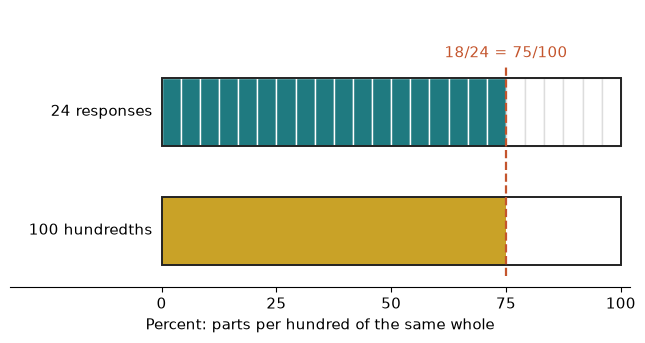

In [5]:
def percent_picture(part=18, whole=24):
    share = Fraction(part, whole)
    pct = float(share) * 100
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for k in range(whole):
        ax.add_patch(Rectangle((k/whole, 1.25), 1/whole, 0.6, facecolor=TEAL if k < part else "white",
                               edgecolor="white" if k < part else LIGHT))
    ax.add_patch(Rectangle((0, 1.25), 1, 0.6, fill=False, edgecolor=INK, lw=1.4))
    for k in range(100):
        ax.add_patch(Rectangle((k/100, 0.2), 1/100, 0.6, facecolor=GOLD if k < pct else "white", edgecolor="none"))
    ax.add_patch(Rectangle((0, 0.2), 1, 0.6, fill=False, edgecolor=INK, lw=1.4))
    ax.plot([float(share)]*2, [0.1, 1.95], color=TERRA, ls="dashed", lw=1.6)
    ax.text(float(share), 2.0, f"{part}/{whole} = {pct:g}/100", ha="center", va="bottom", color=TERRA)
    ax.text(-0.02, 1.55, f"{whole} responses", ha="right", va="center")
    ax.text(-0.02, 0.5, "100 hundredths", ha="right", va="center")
    ax.set_xlim(-0.33, 1.02); ax.set_ylim(0, 2.45)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1]); ax.set_xticklabels(["0", "25", "50", "75", "100"])
    ax.set_xlabel("Percent: parts per hundred of the same whole"); bare(ax)
    plt.show()

percent_picture(18, 24)

**What this shows:** The top bar is the whole, cut into one cell per response. The bottom bar is the same whole cut into 100. The dashed line shows the share reads the same on both: 18 of 24 is 75 of 100. Name the whole first: the same 18 is 75% of 24 but 90% of 20.

**Where it stops working:** This is a part-to-whole ratio, where the part sits inside the whole. A part-to-part ratio, like 2 measures of concentrate to 3 of water, needs the total 5 as the whole first.

## 3. Equal percentages, unequal bases

**Question in plain words:** Up 20%, then down 20%: why not back to 100?

$$100 \times 1.20 \times 0.80 = 96 \qquad\qquad 1.20 \times 0.80 = 0.96$$

**What the symbols mean:** 1.20 keeps the whole and adds twenty hundredths. 0.80 keeps eighty hundredths. Each percent is taken of the amount at that step, its base.

In [6]:
p = 20
start = 100
up = start * p // 100
mid = start + up
down = mid * p // 100
end = mid - down
print(f"first change (increase): {p}% of {start} = {up}")
print(f"  {start} + {up} = {mid}")
print(f"second change (decrease) uses the new base: {p}% of {mid} = {down}")
print(f"  {mid} - {down} = {end}")
print(f"scale factors: 1.20 x 0.80 = {1.20*0.80:.2f}")
print(f"one line: 100 x 1.20 x 0.80 = {end}, which is {start - end} below where it started")

print()
print("Other menu values (increase first, then decrease first):")
for pc in [10, 20, 50]:
    f_up, f_dn = 100 + pc, 100 - pc
    end_up = start * f_up * f_dn / 10000
    print(f"  {pc}%: 100 x {f_up/100:.2f} x {f_dn/100:.2f} = {end_up:g}   (same end either order; {start-end_up:g} below 100)")
print()
print("Chapter practice: 100 x 1.10 = 110, then 10% of 110 = 11, so 110 - 11 = 99; one line 100 x 1.10 x 0.90 = 99")

first change (increase): 20% of 100 = 20
  100 + 20 = 120
second change (decrease) uses the new base: 20% of 120 = 24
  120 - 24 = 96
scale factors: 1.20 x 0.80 = 0.96
one line: 100 x 1.20 x 0.80 = 96, which is 4 below where it started

Other menu values (increase first, then decrease first):
  10%: 100 x 1.10 x 0.90 = 99   (same end either order; 1 below 100)
  20%: 100 x 1.20 x 0.80 = 96   (same end either order; 4 below 100)
  50%: 100 x 1.50 x 0.50 = 75   (same end either order; 25 below 100)

Chapter practice: 100 x 1.10 = 110, then 10% of 110 = 11, so 110 - 11 = 99; one line 100 x 1.10 x 0.90 = 99


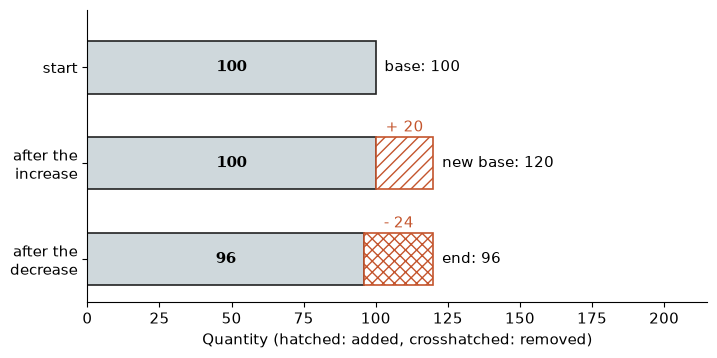

In [7]:
def updown(percent=20):
    start = 100
    mid = start * (100 + percent) / 100
    end = mid * (100 - percent) / 100
    fig, ax = plt.subplots(figsize=(8, 3.8))
    def bar(y, kept, change, label):
        ax.barh([y], [kept], height=0.55, color="#cfd8dc", edgecolor=INK, lw=1.2)
        ax.text(kept/2, y, f"{kept:g}", ha="center", va="center", fontweight="bold")
        right = kept
        if change is not None:
            w = abs(change)
            ax.barh([y], [w], left=kept, height=0.55, color="white", edgecolor=TERRA,
                    hatch="///" if change > 0 else "xxx", lw=1.2)
            ax.text(kept + w/2, y + 0.33, f"{'+' if change > 0 else '-'} {w:g}", ha="center", color=TERRA)
            right += w
        ax.text(right + 3, y, label, va="center")
    bar(2.0, start, None, "base: 100")
    bar(1.0, start, mid - start, f"new base: {mid:g}")
    bar(0.0, end, -(mid - end), f"end: {end:g}")
    ax.set_yticks([2, 1, 0]); ax.set_yticklabels(["start", "after the\nincrease", "after the\ndecrease"])
    ax.set_xlim(0, 215); ax.set_ylim(-0.45, 2.6)
    ax.set_xlabel("Quantity (hatched: added, crosshatched: removed)")
    plt.show()

updown(20)

**What this shows:** Each bar is the quantity after one step. The second change is the same percent as the first, but of a different base (120 instead of 100), so it is a different amount: 24 removed versus 20 added. Multiply the scale factors instead of cancelling the percents: $1.20 \times 0.80 = 0.96$, not 1. The results are 4 below the start.

**Where it stops working:** Each percent is taken of the current amount, not the original. If both were taken of the original 100, they would cancel.

## 4. Price per one ounce

**Question in plain words:** Label A is 18 oz for \$4.50 and Label B is 12 oz for \$3.24. Which costs less per ounce?

$$\frac{\$4.50}{18\,\mathrm{oz}} \qquad 450\div18=25 \qquad 324\div12=27$$

**What the symbols mean:** Prices are written in cents to keep the numbers short: \$4.50 is 450 cents, and 25 cents per ounce is \$0.25 per ounce. Either is a unit rate: the price of one ounce. These are made-up labels, not real products.

In [8]:
a_cents, a_oz = 450, 18
b_cents, b_oz = 324, 12
rate_a = Fraction(a_cents, a_oz)
rate_b = Fraction(b_cents, b_oz)
print(f"Label A: $4.50 for {a_oz} oz = {a_cents} cents for {a_oz} oz")
print(f"Label B: $3.24 for {b_oz} oz = {b_cents} cents for {b_oz} oz")
print(f"A per ounce: {a_cents} / {a_oz} = {float(rate_a):g} cents")
print(f"B per ounce: {b_cents} / {b_oz} = {float(rate_b):g} cents")
print("lower unit price: Label A")
print(f"check by multiplying back: {a_oz} x {float(rate_a):g} = {a_oz*rate_a}, and {b_oz} x {float(rate_b):g} = {b_oz*rate_b}")

print()
print("Other Label B prices and sizes (A stays 25 cents per ounce):")
for c, o in [(324,12),(300,12),(270,12),(324,10),(300,10),(270,10)]:
    r = Fraction(c, o)
    win = "A" if rate_a < r else ("tie" if rate_a == r else "B")
    print(f"  B = {c} cents for {o} oz: {c} / {o} = {float(r):g} cents per ounce, lower: {win}")
print()
print("Chapter practice: 360 / 15 =", 360//15, "and 250 / 10 =", 250//10, "cents per ounce; check 15 x 24 =", 15*24)

Label A: $4.50 for 18 oz = 450 cents for 18 oz
Label B: $3.24 for 12 oz = 324 cents for 12 oz
A per ounce: 450 / 18 = 25 cents
B per ounce: 324 / 12 = 27 cents
lower unit price: Label A
check by multiplying back: 18 x 25 = 450, and 12 x 27 = 324

Other Label B prices and sizes (A stays 25 cents per ounce):
  B = 324 cents for 12 oz: 324 / 12 = 27 cents per ounce, lower: A
  B = 300 cents for 12 oz: 300 / 12 = 25 cents per ounce, lower: tie
  B = 270 cents for 12 oz: 270 / 12 = 22.5 cents per ounce, lower: B
  B = 324 cents for 10 oz: 324 / 10 = 32.4 cents per ounce, lower: A
  B = 300 cents for 10 oz: 300 / 10 = 30 cents per ounce, lower: A
  B = 270 cents for 10 oz: 270 / 10 = 27 cents per ounce, lower: A

Chapter practice: 360 / 15 = 24 and 250 / 10 = 25 cents per ounce; check 15 x 24 = 360


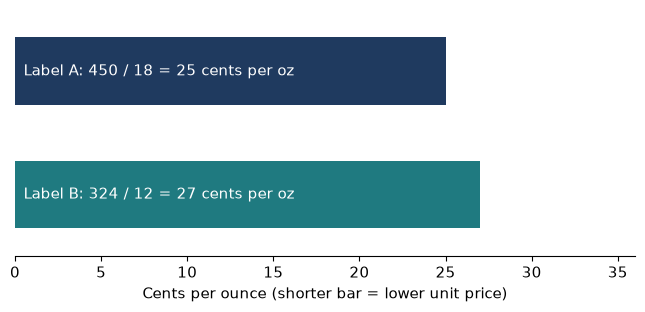

In [9]:
def unit_price(b_cents=324, b_oz=12):
    ra, rb = 450/18, b_cents/b_oz
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh([1.3], [ra], height=0.55, color=NAVY)
    ax.barh([0.3], [rb], height=0.55, color=TEAL)
    ax.text(0.5, 1.3, f"Label A: 450 / 18 = {ra:g} cents per oz", va="center", color="white")
    ax.text(0.5, 0.3, f"Label B: {b_cents} / {b_oz} = {rb:g} cents per oz", va="center", color="white")
    ax.set_xlim(0, 36); ax.set_ylim(-0.2, 1.8)
    ax.set_xlabel("Cents per ounce (shorter bar = lower unit price)"); bare(ax)
    plt.show()

unit_price(324, 12)

**What this shows:** Each bar is a unit price: the label's cents divided by its ounces. Both bars now answer the same question, so the shorter bar (A, at 25) is the lower price per ounce. To compare two sizes, divide each price by its own amount, then compare the per-one answers, and multiply back to check.

**Where it stops working:** Unit price is the only thing compared. A lower unit price is not a recommendation to buy: you still have to use what you buy.

## Practice

**1.** What is the ratio of a 12 oz package to a 6 oz package, and of the 6 oz to the 12 oz?

<details><summary>Show answer</summary>

$12\ \text{oz} / 6\ \text{oz} = 2$, and $6\ \text{oz} / 12\ \text{oz} = 1/2$. The order chose which package counts as one.
</details>

**2.** Seven of twenty responses are incomplete. What percent is that?

<details><summary>Show answer</summary>

$7 / 20 = 0.35$, and $0.35 \times 100 = 35$, so 35%. Check: $0.35 \times 20 = 7$.
</details>

**3.** Start at 100, rise 10%, then fall 10%. What is the result?

<details><summary>Show answer</summary>

$100 \times 1.10 = 110$, then 10% of 110 is 11, so $110 - 11 = 99$. In one line: $100 \times 1.10 \times 0.90 = 99$.
</details>

**4.** Fifteen ounces cost \$3.60 and ten ounces cost \$2.50. Which is lower per ounce?

<details><summary>Show answer</summary>

$360 / 15 = 24$ and $250 / 10 = 25$ cents per ounce, so the 15 oz label is lower. Check: $15 \times 24 = 360$.
</details>